## Import Libs


In [21]:
import cv2
import os
from tqdm.auto import tqdm
# ============================================================
import src.utils as ut
# ============================================================
import importlib
importlib.reload(ut)
# ============================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib import colormaps
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

# ============================================================

import os
import cv2
import numpy as np
import pandas as pd

from pathlib import Path
from skimage import filters
from skimage.morphology import skeletonize, disk
from skimage.util import img_as_ubyte
from skimage.filters.rank import entropy
from skimage.metrics import (
    peak_signal_noise_ratio as psnr,
    mean_squared_error as mse,
    structural_similarity as ssim
)

from src.functions import calculate_epi

# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# ============================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

# ============================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from skimage import filters
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

# ============================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from skimage import filters
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

# ============================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from skimage import filters
from skimage.morphology import skeletonize
from skimage.util import img_as_ubyte

## Set Paths

In [22]:
paths_results = "results"
paths_results_data = "data/processed"
paths_datasets = "/Users/rashid/data/DS/Healthcare/Breast/CHSJ/BreastCancer_Benign"

## Data Preprocessing

In [23]:
# Input and output folders
input_folder = paths_datasets #r"C:/programming/pythonML/computerVision/Breast_cancer/datasets"

output_grayscale = f"{paths_results_data}/grayscale"
output_folder = f"{paths_results_data}/sekeletal"
os.makedirs(output_grayscale, exist_ok=True)

# Collect image files
image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif'))]

# Exception if folder is empty
if not image_files:
    raise FileNotFoundError(f"No images found in folder: {input_folder}")

for filename in tqdm(image_files, desc="Processing images"):
    filepath = os.path.join(input_folder, filename)

    # Load image
    image = cv2.imread(filepath, cv2.IMREAD_COLOR)
    if image is None:
        # print(f"⚠️ Skipping unreadable file: {filename}")
        continue

    # Shared preprocessing: resize (150x200) -> grayscale -> background removal
    _, gray_image, mask = ut.fun_preprocess(image)

    # Save grayscale image
    save_path = os.path.join(output_grayscale, f"gray_{filename}")
    cv2.imwrite(save_path, gray_image)
    # print(f"✅ Saved: {save_path}")

print("\nProcessing complete!")


Processing images: 100%|██████████| 2520/2520 [00:03<00:00, 672.28it/s]


Processing complete!


## Apply Filter

Saving results to: data/processed/vht/


Processing images: 100%|██████████| 2520/2520 [00:10<00:00, 237.24it/s]


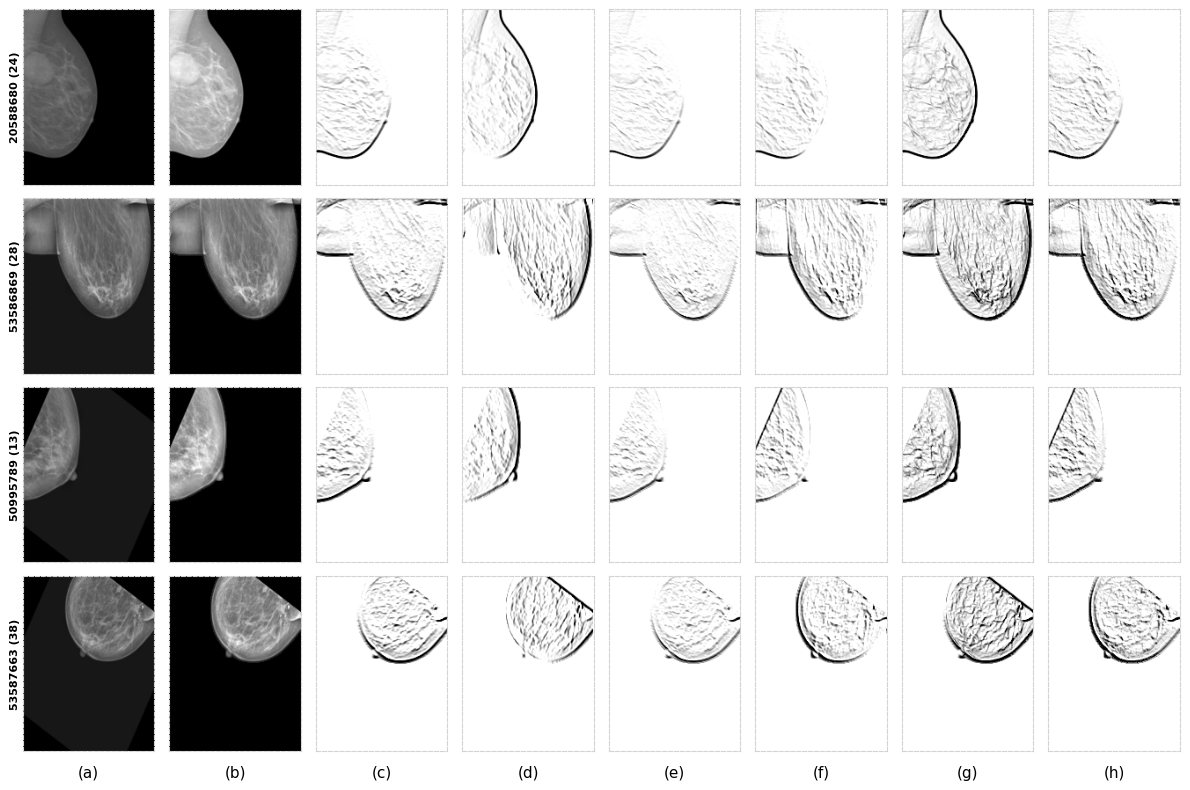

In [24]:
# Input & Output folders
input_folder = paths_datasets #r"C:/programming/pythonML/computerVision/Breast_cancer/datasets"
output_folder = f"{paths_results_data}/vht/"
output_combined = f"{paths_results_data}/combined/"
os.makedirs(output_folder, exist_ok=True)

print("Saving results to:", output_folder)

# Collect image files
image_files = [f for f in os.listdir(input_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif'))]
if not image_files:
    raise FileNotFoundError(f"No images found in folder: {input_folder}")

all_results = []

# Custom filters
edge_filter_45 = np.array([[ 2, 2, 0],
                           [-2, 0, 2],
                           [0, -2, -2]])
edge_filter_y = np.array([[2, 0, -2],
                          [2, 0, -2],
                          [2, 0, -2]])
edge_filter_135 = np.array([[0, 2, 2],
                            [-2, 0, 2],
                            [-2, -2, 0]])
edge_filter_x = np.array([[ 2,  2,  2],
                          [ 0,  0,  0],
                          [-2, -2, -2]])

# Loop through dataset
for filename in tqdm(image_files, desc="Processing images"):
    filepath = os.path.join(input_folder, filename)
    image = cv2.imread(filepath, cv2.IMREAD_COLOR)  # Load color
    if image is None:
        print(f"⚠️ Skipping unreadable file: {filename}")
        continue
    


    # Resized colour image (only for the first column of the grid)
    image_resized = cv2.resize(image, ut.PREPROCESS_SIZE, interpolation=cv2.INTER_AREA)

    # Shared preprocessing: resize (150x200) -> grayscale -> background removal
    _, gray_image, mask = ut.fun_preprocess(image)

    # ---- Edge detection using custom filters ----
    Edge_result_x = cv2.filter2D(gray_image, -1, edge_filter_x)
    Edge_result_y = cv2.filter2D(gray_image, -1, edge_filter_y)
    Edge_result_diag = cv2.filter2D(gray_image, -1, edge_filter_45)
    Edge_result_antidiag = cv2.filter2D(gray_image, -1, edge_filter_135)

    # Combine edges
    combined_xy = cv2.bitwise_or(Edge_result_x, Edge_result_y)
    combined_yx = cv2.bitwise_or(Edge_result_diag, Edge_result_antidiag)

    # 🔄 Processed set for visualization
    processed_set = [
        cv2.cvtColor(image_resized, cv2.COLOR_BGR2RGB),  # Original input in color
        gray_image,                                      # Grayscale
        cv2.bitwise_not(Edge_result_x),                  # X
        cv2.bitwise_not(Edge_result_y),                  # Y
        cv2.bitwise_not(Edge_result_diag),               # Diag
        cv2.bitwise_not(Edge_result_antidiag),           # Anti-Diag
        cv2.bitwise_not(combined_xy),                    # Combined XY
        cv2.bitwise_not(combined_yx)                     # Combined YX
    ]

    all_results.append(processed_set)

    # --- Save each variation in processed folder ---
    base_name, _ = os.path.splitext(filename)
    save_variations = {
        "Gray": gray_image,
        "Edge_vht_x": cv2.bitwise_not(Edge_result_x),
        "Edge_vht_y": cv2.bitwise_not(Edge_result_y),
        "Edge_vht_diag": cv2.bitwise_not(Edge_result_diag),
        "Edge_vht_antidiag": cv2.bitwise_not(Edge_result_antidiag),
        "Combined_xy": cv2.bitwise_not(combined_xy),
        "Combined_yx": cv2.bitwise_not(combined_yx)
    }
         
    for key, img in save_variations.items():
        out_path = os.path.join(output_folder, f"{base_name}_{key}.png")
        success = cv2.imwrite(out_path, img)

    cv2.imwrite(os.path.join(output_combined, f"{base_name}_xy.png"), cv2.bitwise_not(combined_xy))
    cv2.imwrite(os.path.join(output_combined, f"{base_name}_yx.png"), cv2.bitwise_not(combined_yx))

    
      #   if success:
      #       # print(f"✅ Saved: {out_path}")
      #   else:
      #       print(f"❌ Failed to save: {out_path}")


# --- Plot Grid (just first few for visualization) ---
cols = 8
rows = min(4, len(all_results))  # show max 4 images in grid
fig, axes = plt.subplots(rows, cols, figsize=(12, rows * 2))

# col_titles = ["Original", "Gray", "X-axis", "Y-axis", "Diag", "Anti-Diag", "Combined_xy", "Combined_yx"]

for r in range(rows):
    for c in range(cols):
        ax = axes[r, c] if rows > 1 else axes[c]
        if c == 0:
            ax.imshow(all_results[r][c])  # RGB color for original
        else:
            ax.imshow(all_results[r][c], cmap='gray')
        ax.set_xticks([]), ax.set_yticks([])
       
        # Light gray dashed axes
        for spine in ax.spines.values():
            spine.set_edgecolor("lightgray")
            spine.set_linestyle("--")
            spine.set_linewidth(0.8)
            
        # if r == 0:
        #     ax.set_title(col_titles[c], fontsize=9, pad=2)
        if c == 0:
            ax.set_ylabel(image_files[r], fontsize=8, rotation=90, labelpad=2, weight='bold')
            
        import string
labels = [f"({ch})" for ch in string.ascii_lowercase]

for r in range(rows):
    for c in range(cols):
        ax = axes[r, c] if rows > 1 else axes[c]

        # ✅ remove extension before using as ylabel
        if c == 0:
            # get filename without extension
            name_without_ext = os.path.splitext(image_files[r])[0]
            ax.set_ylabel(name_without_ext,
                          fontsize=8, rotation=90, labelpad=2, weight='bold')

        # ✅ Only add (a), (b), … under the last row
        if r == rows - 1:
            ax.set_xlabel(labels[c], fontsize=11, labelpad=10)


plt.tight_layout()
# Save the figure all in graphs folder
out_dir = f"{paths_results_data}/graphs"
os.makedirs(out_dir, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"Proposed NIVHT All Variations.{ext}"), **save_params)
plt.show()

Processing combined images: 100%|██████████| 5040/5040 [00:05<00:00, 945.02it/s] 


Saved: data/processed/graphs/NIVHT_skeletonization_and_edge_thinning.png
Saved: data/processed/graphs/NIVHT_skeletonization_and_edge_thinning.pdf
Saved: data/processed/graphs/NIVHT_skeletonization_and_edge_thinning.svg


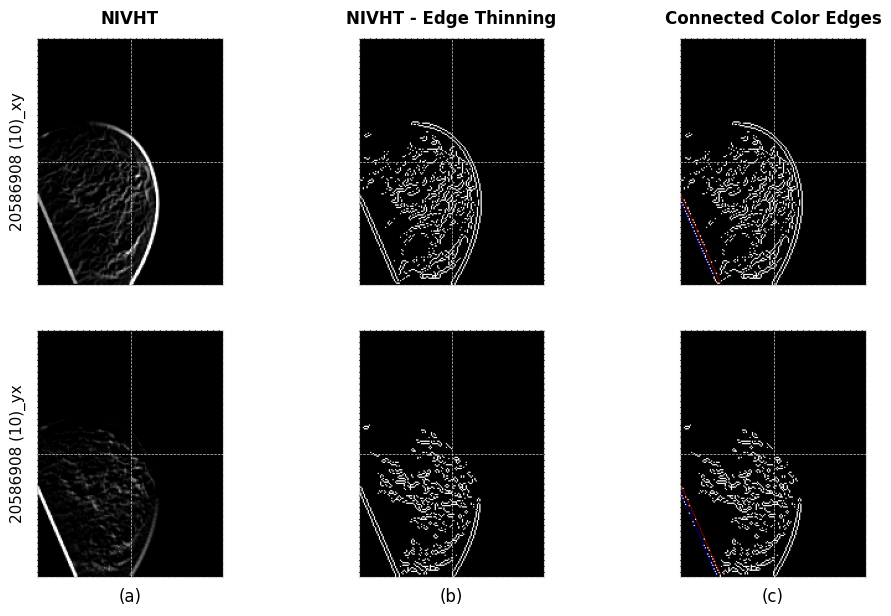

In [25]:

# ============================================================
# CONFIGURATION
# ============================================================

combined_folder = Path(paths_results_data) / "combined"
out_dir = Path(paths_results_data) / "graphs"

out_dir.mkdir(parents=True, exist_ok=True)

NROWS = 2
NCOLS = 3

HOUGH_THRESHOLD = 50
MIN_LINE_LENGTH = 10
MAX_LINE_GAP = 5

SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg"}

# ============================================================
# LOAD INPUT FILES
# ============================================================

combined_files = sorted(
    [
        p for p in combined_folder.iterdir()
        if p.suffix.lower() in SUPPORTED_EXTENSIONS
    ]
)

if not combined_files:
    raise FileNotFoundError(
        f"No combined images found in: {combined_folder}"
    )

all_results = []

# ============================================================
# PROCESS EACH IMAGE
# ============================================================

for filepath in tqdm(combined_files, desc="Processing combined images"):

    filename = filepath.name
    title = filepath.stem

    img = cv2.imread(
        str(filepath),
        cv2.IMREAD_GRAYSCALE
    )

    if img is None:
        print(f"Skipping unreadable image: {filename}")
        continue

    # --------------------------------------------------------
    # 1. NIVHT INPUT
    # --------------------------------------------------------

    img = cv2.bitwise_not(img)

    # --------------------------------------------------------
    # 2. HISTOGRAM EQUALIZATION AND HIGH-INTENSITY MASK
    # --------------------------------------------------------

    img_eq = cv2.equalizeHist(img)

    _, high_intensity = cv2.threshold(
        img_eq,
        100,
        255,
        cv2.THRESH_BINARY
    )

    # --------------------------------------------------------
    # 3. CANNY EDGE EXTRACTION
    # --------------------------------------------------------

    edges = cv2.Canny(img,threshold1=50,threshold2=200)

    combined_edges = cv2.bitwise_and(
        edges,
        high_intensity
    )

    # --------------------------------------------------------
    # 4. EDGE THINNING (SKELETONIZATION)
    # --------------------------------------------------------

    skeleton = skeletonize(combined_edges > 0)

    thin_edges = img_as_ubyte(skeleton)

    # --------------------------------------------------------
    # 5. HOUGH LINE DETECTION
    # --------------------------------------------------------

    lines = cv2.HoughLinesP(thin_edges,rho=1,theta=np.pi / 180,threshold=HOUGH_THRESHOLD,minLineLength=MIN_LINE_LENGTH,maxLineGap=MAX_LINE_GAP)


    colored_lines = cv2.cvtColor(thin_edges,cv2.COLOR_GRAY2BGR)

    num_lines = 0
    average_length = 0.0

    if lines is not None and len(lines) > 0:

        # IMPORTANT: Works with (N, 1, 4) and (N, 4)
        lines = np.asarray(lines).reshape(-1, 4)

        # Float conversion prevents integer overflow
        coords = lines.astype(np.float64)

        dx = coords[:, 2] - coords[:, 0]
        dy = coords[:, 3] - coords[:, 1]

        lengths = np.hypot(dx, dy)

        num_lines = len(lines)
        average_length = float(np.mean(lengths))

        # Normalize segment lengths
        minimum = lengths.min()
        maximum = lengths.max()

        if maximum > minimum:
            lengths_norm = (
                (lengths - minimum) /
                (maximum - minimum)
            )
        else:
            lengths_norm = np.zeros_like(lengths)

        # Color-code line segments
        cmap = colormaps["jet"]

        for (x1, y1, x2, y2), ln in zip(
            lines,
            lengths_norm
        ):

            rgb = cmap(float(ln))[:3]

            bgr = tuple(
                int(255 * value)
                for value in rgb[::-1]
            )

            cv2.line(
                colored_lines,
                (int(x1), int(y1)),
                (int(x2), int(y2)),
                bgr,
                thickness=1,
                lineType=cv2.LINE_8
            )

    # --------------------------------------------------------
    # 6. COLLECT THREE VISUALIZATIONS
    # --------------------------------------------------------

    all_results.append(
        {
            "title": title,
            "images": [
                img,
                thin_edges,
                colored_lines
            ],
            "num_lines": num_lines,
            "average_length": average_length
        }
    )
    #  MOVE TO LOGGING SECTION
    # print(
    #     f"{filename}: "
    #     f"segments={num_lines}, "
    #     f"average_length={average_length:.2f} px"
    # )

# ============================================================
# CREATE PUBLICATION FIGURE: 2 ROWS x 3 COLUMNS
# ============================================================

if not all_results:
    raise RuntimeError("No readable images were processed.")

subset_results = all_results[:NROWS]

fig, axes = plt.subplots(NROWS,NCOLS,figsize=(12, 7),squeeze=False)

column_titles = [
    "NIVHT",
    "NIVHT - Edge Thinning",
    "Connected Color Edges"
]

column_labels = [
    "(a)",
    "(b)",
    "(c)"
]

for r in range(NROWS):

    for c in range(NCOLS):

        ax = axes[r, c]

        # Hide unused rows
        if r >= len(subset_results):
            ax.axis("off")
            continue

        result = subset_results[r]
        img = result["images"][c]

        # -----------------------------------------------
        # Display image
        # -----------------------------------------------

        if img.ndim == 2:
            ax.imshow(
                img,
                cmap="gray",
                vmin=0,
                vmax=255
            )
        else:
            ax.imshow(
                cv2.cvtColor(
                    img,
                    cv2.COLOR_BGR2RGB
                )
            )

        # -----------------------------------------------
        # Column titles
        # -----------------------------------------------

        if r == 0:
            ax.set_title(column_titles[c],fontsize=12,fontweight="bold",pad=10)

        # -----------------------------------------------
        # Row labels
        # -----------------------------------------------

        if c == 0:
            ax.set_ylabel(result["title"],fontsize=11,labelpad=8)

        # -----------------------------------------------
        # Center reference lines
        # -----------------------------------------------

        h, w = img.shape[:2]

        ax.axhline(h / 2,color="lightgray",linestyle="--",linewidth=0.5)

        ax.axvline(w / 2,color="lightgray",linestyle="--",linewidth=0.5)

        # -----------------------------------------------
        # Panel borders
        # -----------------------------------------------

        for spine in ax.spines.values():
            spine.set_edgecolor("lightgray")
            spine.set_linestyle("--")
            spine.set_linewidth(0.8)

        ax.set_xticks([])
        ax.set_yticks([])

        # Panel labels only on last row
        if r == NROWS - 1:
            ax.set_xlabel(
                column_labels[c],
                fontsize=12,
                labelpad=8
            )

# ============================================================
# SAVE FIGURE
# ============================================================

plt.subplots_adjust(
    wspace=0.12,
    hspace=0.18
)

filename = "NIVHT_skeletonization_and_edge_thinning"

for ext in ["png", "pdf", "svg"]:

    output_path = out_dir / f"{filename}.{ext}"

    plt.savefig(
        output_path,
        dpi=300,
        transparent=False,
        bbox_inches="tight",
        pad_inches=0.05
    )

    print(f"Saved: {output_path}")

plt.show()
plt.close(fig)


## Calculate the results using all classical and propossed method

In [26]:
# ============================================================
# 1. CONFIGURATION
# ============================================================

combined_folder = Path(paths_results_data) / "combined"
save_folder = Path(paths_results_data) / "metrics"

save_folder.mkdir(parents=True, exist_ok=True)

output_excel = save_folder / "edge_metrics.xlsx"
output_csv = save_folder / "edge_metrics.csv"

# Fixed threshold for normalized gradient outputs [0, 1]
GRADIENT_THRESHOLD = 0.10

method_labels = [
    "Original",
    "Roberts",
    "Sobel",
    "Canny",
    "Prewitt",
    "Laplacian",
    "Proposed"
]

columns = [
    "Image",
    "Method",
    "Number_of_Edges",
    "Edge_Density",
    "EPI",
    "Entropy",
    "PSNR",
    "MSE",
    "SSIM",
    "Avg_Edge_Length",
    "Max_Edge_Length",
    "Min_Edge_Length",
    "Hough_Segments",
    "Connected_Components"
]


# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def gradient_to_uint8(gradient):
    """
    Convert a normalized gradient magnitude image from [0,1]
    to uint8 [0,255].
    """
    gradient = np.asarray(gradient, dtype=np.float32)
    gradient = np.clip(gradient, 0.0, 1.0)
    return np.round(gradient * 255).astype(np.uint8)


def gradient_to_binary(gradient, threshold=GRADIENT_THRESHOLD):
    """
    Convert normalized gradient magnitude to a binary map.
    A common fixed threshold is used for gradient operators.
    """
    return (
        np.asarray(gradient) >= threshold
    ).astype(np.uint8) * 255


def get_hough_metrics(edge_bin):
    """
    Compute lengths of Hough-detected straight-line segments.

    Supports both (N,1,4) and (N,4) line array shapes.
    """

    lines = cv2.HoughLinesP(
        edge_bin,
        rho=1,
        theta=np.pi / 180,
        threshold=50,
        minLineLength=5,
        maxLineGap=5
    )

    if lines is None or len(lines) == 0:
        return 0.0, 0.0, 0.0, 0

    # FIX: Normalize shape
    lines = np.asarray(lines).reshape(-1, 4)

    # Avoid integer overflow during subtraction
    coords = lines.astype(np.float64)

    dx = coords[:, 2] - coords[:, 0]
    dy = coords[:, 3] - coords[:, 1]

    lengths = np.hypot(dx, dy)

    return (
        float(np.mean(lengths)),
        float(np.max(lengths)),
        float(np.min(lengths)),
        int(len(lengths))
    )


def get_connected_components(edge_bin):
    """Number of 8-connected foreground components."""

    foreground = (edge_bin > 0).astype(np.uint8)

    num_labels, labels = cv2.connectedComponents(
        foreground,
        connectivity=8
    )

    return int(num_labels - 1)


def compute_metrics(reference, edge_image, edge_binary):
    """
    Compute quantitative metrics against the reference image.

    PSNR, MSE, SSIM are calculated from the intensity/edge map.
    Edge statistics are calculated from the binary edge map.
    """

    reference = reference.astype(np.uint8)
    edge_image = edge_image.astype(np.uint8)
    edge_binary = edge_binary.astype(np.uint8)

    if reference.shape != edge_image.shape:
        raise ValueError("Image shapes do not match.")

    # ----------------------------------------------
    # Edge statistics
    # ----------------------------------------------

    num_edges = int(np.count_nonzero(edge_binary))
    total_pixels = edge_binary.size
    edge_density = num_edges / total_pixels

    # ----------------------------------------------
    # Edge Preservation Index
    # ----------------------------------------------

    epi = float(calculate_epi(reference, edge_binary))

    # ----------------------------------------------
    # Entropy (local, radius=3)
    # ----------------------------------------------

    ent = float(entropy(edge_binary, disk(3)).mean())

    # ----------------------------------------------
    # Image similarity
    # ----------------------------------------------

    mse_val = float(mse(reference, edge_image))

    psnr_val = (
        float("inf")
        if mse_val == 0
        else float(psnr(reference, edge_image, data_range=255))
    )

    ssim_val = float(
        ssim(reference, edge_image, data_range=255)
    )

    # ----------------------------------------------
    # Hough line measurements
    # ----------------------------------------------

    avg_len, max_len, min_len, n_segments = (
        get_hough_metrics(edge_binary)
    )

    # ----------------------------------------------
    # Connected component count
    # ----------------------------------------------

    connected_components = get_connected_components(
        edge_binary
    )

    return {
        "Number_of_Edges": num_edges,
        "Edge_Density": edge_density,
        "EPI": epi,
        "Entropy": ent,
        "PSNR": psnr_val,
        "MSE": mse_val,
        "SSIM": ssim_val,
        "Avg_Edge_Length": avg_len,
        "Max_Edge_Length": max_len,
        "Min_Edge_Length": min_len,
        "Hough_Segments": n_segments,
        "Connected_Components": connected_components
    }


# ============================================================
# 3. COLLECT IMAGES
# ============================================================

combined_files = sorted(
    [
        f for f in combined_folder.iterdir()
        if f.suffix.lower() in {
            ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
        }
    ]
)
#  CHANGE IT LATER
combined_files = combined_files[:50]  # Limit to first 50 images for testing
if not combined_files:
    raise FileNotFoundError(
        f"No images found in: {combined_folder}"
    )

print(f"Found {len(combined_files)} images.")

all_metrics = []


# ============================================================
# 4. PROCESS EACH IMAGE
# ============================================================

for image_idx, filepath in enumerate(tqdm(combined_files), start=1):

    filename = filepath.name

    img = cv2.imread(
        str(filepath),
        cv2.IMREAD_GRAYSCALE
    )

    if img is None:
        print(f"Skipping unreadable file: {filename}")
        continue

    # Preserve the inversion in your original implementation
    img_inv = cv2.bitwise_not(img)

    # --------------------------------------------------------
    # Classical edge detectors
    # --------------------------------------------------------

    roberts_float = filters.roberts(img_inv)
    sobel_float = filters.sobel(img_inv)
    prewitt_float = filters.prewitt(img_inv)

    canny_edges = cv2.Canny(img_inv, 50, 150)

    laplacian_float = cv2.Laplacian(
        img_inv,
        cv2.CV_32F
    )

    laplacian_abs = np.abs(laplacian_float)

    # Use a fixed 8-bit scaling for Laplacian visual output
    laplacian_uint8 = np.clip(
        laplacian_abs, 0, 255
    ).astype(np.uint8)

    # --------------------------------------------------------
    # Proposed post-processing (current implementation)
    # --------------------------------------------------------

    img_eq = cv2.equalizeHist(img_inv)

    _, high_intensity = cv2.threshold(
        img_eq,
        100,
        255,
        cv2.THRESH_BINARY
    )

    edges_canny = cv2.Canny(
        img_inv,
        50,
        200
    )

    combined_edges = cv2.bitwise_and(
        edges_canny,
        high_intensity
    )

    skeleton = skeletonize(
        combined_edges > 0
    )

    thin_edges = img_as_ubyte(skeleton)

    # --------------------------------------------------------
    # Images and binary maps for each method
    # --------------------------------------------------------

    method_outputs = {
        "Original": (
            img_inv,
            (img_inv > 0).astype(np.uint8) * 255
        ),
        "Roberts": (
            gradient_to_uint8(roberts_float),
            gradient_to_binary(roberts_float)
        ),
        "Sobel": (
            gradient_to_uint8(sobel_float),
            gradient_to_binary(sobel_float)
        ),
        "Canny": (
            canny_edges,
            canny_edges
        ),
        "Prewitt": (
            gradient_to_uint8(prewitt_float),
            gradient_to_binary(prewitt_float)
        ),
        "Laplacian": (
            laplacian_uint8,
            (laplacian_uint8 >= 26).astype(np.uint8) * 255
        ),
        "Proposed": (
            thin_edges,
            thin_edges
        )
    }

    # --------------------------------------------------------
    # Calculate metrics for each method
    # --------------------------------------------------------

    for method_name in method_labels:

        edge_img, edge_bin = method_outputs[method_name]

        values = compute_metrics(
            img_inv,
            edge_img,
            edge_bin
        )

        row = {
            "Image": filename,
            "Method": method_name,
            **values
        }

        all_metrics.append(row)

    if image_idx % 25 == 0 or image_idx == len(combined_files):
        print(
            f"Processed {image_idx}/{len(combined_files)} images"
        )


# ============================================================
# 5. CREATE DATAFRAME
# ============================================================

metrics_df = pd.DataFrame(
    all_metrics,
    columns=columns
)

if metrics_df.empty:
    raise RuntimeError("No valid images were processed.")

# Original is retained for reference but not considered
# a competing edge-detection method.

comparison_df = metrics_df[
    metrics_df["Method"] != "Original"
].copy()


# ============================================================
# 6. SUMMARY STATISTICS
# ============================================================

numeric_columns = comparison_df.select_dtypes(
    include=[np.number]
).columns

# Avoid infinite PSNR values distorting summary statistics
summary_input = comparison_df.replace(
    [np.inf, -np.inf],
    np.nan
)

summary_df = (
    summary_input
    .groupby("Method")[numeric_columns]
    .agg(["mean", "std", "median", "min", "max"])
)

summary_df.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary_df.columns
]

summary_df = summary_df.reset_index()


# ============================================================
# 7. EXPORT TO EXCEL AND CSV
# ============================================================

metrics_df.to_csv(
    output_csv,
    index=False
)

with pd.ExcelWriter(
    output_excel,
    engine="openpyxl"
) as writer:

    metrics_df.to_excel(
        writer,
        sheet_name="All_Metrics",
        index=False
    )

    comparison_df.to_excel(
        writer,
        sheet_name="Method_Comparison",
        index=False
    )

    summary_df.to_excel(
        writer,
        sheet_name="Summary_Statistics",
        index=False
    )

print("\nEvaluation completed successfully.")
print(f"Excel: {output_excel}")
print(f"CSV:   {output_csv}")
print(f"Images: {metrics_df['Image'].nunique()}")
print(f"Total evaluation rows: {len(metrics_df)}")

print("\nSummary of edge-detection methods:")
print(
    summary_df[
        [
            "Method",
            "Number_of_Edges_mean",
            "Edge_Density_mean",
            "EPI_mean",
            "Connected_Components_mean"
        ]
    ].to_string(index=False)
)


Found 50 images.


 56%|█████▌    | 28/50 [00:01<00:01, 17.54it/s]

Processed 25/50 images


100%|██████████| 50/50 [00:02<00:00, 17.13it/s]


Processed 50/50 images

Evaluation completed successfully.
Excel: data/processed/metrics/edge_metrics.xlsx
CSV:   data/processed/metrics/edge_metrics.csv
Images: 50
Total evaluation rows: 350

Summary of edge-detection methods:
   Method  Number_of_Edges_mean  Edge_Density_mean  EPI_mean  Connected_Components_mean
    Canny               3323.68           0.110789  0.501017                     133.46
Laplacian               6405.34           0.213511  0.360728                      94.80
  Prewitt               5150.46           0.171682  0.361946                      68.76
 Proposed               1682.78           0.056093  0.562150                     339.26
  Roberts               4760.22           0.158674  0.512014                      73.50
    Sobel               5235.04           0.174501  0.370774                      61.28


## DONE

Processing combined images: 100%|██████████| 5/5 [00:00<00:00, 143.39it/s]


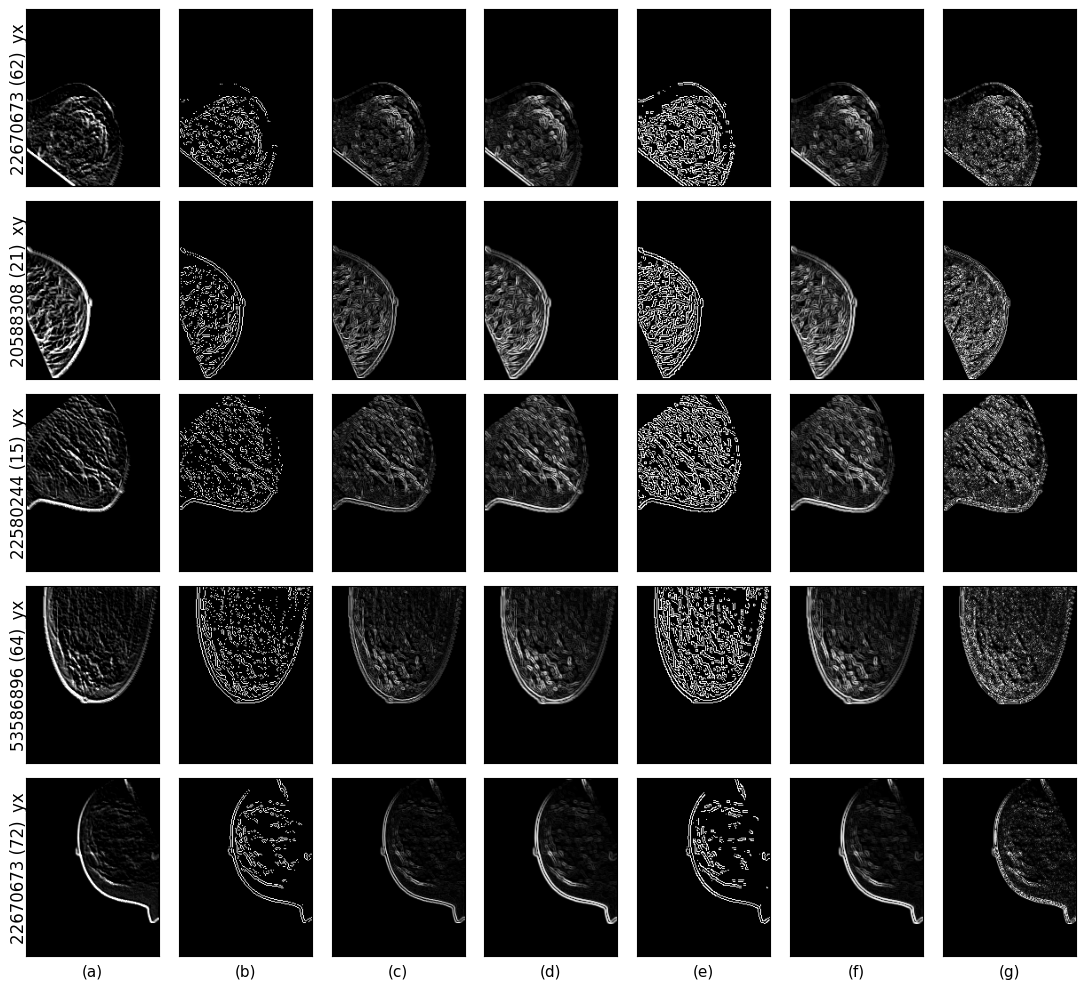

In [27]:

# --- Paths ---
combined_folder = f"{paths_results_data}/combined/"
output_edges_comp = f"{paths_results_data}/comp_analysis/"

# Collect images
combined_files = [f for f in os.listdir(combined_folder) 
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

combined_files = combined_files[:5]  # Limit to first 5 images for display
if not combined_files:
    raise FileNotFoundError(f"No images found in: {combined_folder}")
# base_name, _ = os.path.splitext(filename)
# --- Edge detection method labels ---
method_labels = ["Proposed NIVHT", "Edge Thinning NIVHT", "Roberts", "Sobel", "Canny", "Prewitt", "Laplacian"]
ncols = len(method_labels)
nrows = len(combined_files)

# --- Create grid ---
fig, axes = plt.subplots(nrows, ncols, figsize=(2 * ncols, 2 * nrows))

for r, filename in enumerate(tqdm(combined_files, desc="Processing combined images")):
    filepath = os.path.join(combined_folder, filename)
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"⚠️ Skipping unreadable file: {filename}")
        
        continue
    img = cv2.bitwise_not(img)
    # --- Edge Detection Methods ---
    roberts_edges = filters.roberts(img)
    sobel_edges = filters.sobel(img)
    prewitt_edges = filters.prewitt(img)
    canny_edges = cv2.Canny(img, 120, 150)
    laplacian_edges = cv2.Laplacian(img, cv2.CV_64F)
    laplacian_edges = np.uint8(np.absolute(laplacian_edges))

    # --- Proposed method: skeletonized combined edges ---
    img_eq = cv2.equalizeHist(img)
    _, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)
    edges_canny = cv2.Canny(img, 50, 200)
    combined_edges = cv2.bitwise_and(edges_canny, high_intensity)
    binary = combined_edges > 0
    skeleton = skeletonize(binary)
    thin_edges = img_as_ubyte(skeleton)

    # --- Collect results ---
    save_set = [roberts_edges, sobel_edges, canny_edges,
                  prewitt_edges, laplacian_edges, thin_edges]

    # --- Save each result image ---
    base_name = os.path.splitext(filename)[0]
    for method_name, edge_img in zip(method_labels, save_set):
        save_path = os.path.join(output_edges_comp, f"{base_name}_{method_name}.png")
        # Convert to uint8 if float
        if edge_img.dtype in [np.float32, np.float64]:
            edge_img = np.uint8(edge_img * 255)
        cv2.imwrite(save_path, edge_img)

    result_set = [img, thin_edges, roberts_edges, sobel_edges, canny_edges,
                  prewitt_edges, laplacian_edges]

    # --- Display in grid ---
    for c, image_to_show in enumerate(result_set):
        ax = axes[r, c] if nrows > 1 else axes[c]

        # Show grayscale or RGB
        if image_to_show.ndim == 2:
            ax.imshow(image_to_show, cmap="gray")
        else:
            ax.imshow(cv2.cvtColor(image_to_show, cv2.COLOR_BGR2RGB))
        # Remove tick
        ax.set_xticks([]), ax.set_yticks([])
        # Add row label (vertical) for first column
        if c == 0:
            ax.set_ylabel(os.path.splitext(filename)[0],fontsize=8,rotation=90, labelpad=5, va='center', ha='center')
        # Add column labels at top for first row
        # if r == 0:
        #     ax.set_title(method_labels[c], fontsize=9)
        #     plt.subplots_adjust(left=0.6, right=2.5, top=1, bottom=0.6, wspace=0.02, hspace=0.04)

# Add row label (vertical) for first column
        if c == 0:
            ax.set_ylabel(os.path.splitext(filename)[0],fontsize=12, rotation=90, labelpad=5,va='center', ha='center')

        # Add column labels at top for first row
        # if r == 0:
        #     ax.set_title(method_labels[c], fontsize=9)

        # ✅ Add caption (a), (b), (c)... only under LAST row
        if r == nrows - 1:
            ax.set_xlabel(labels[c], fontsize=11, labelpad=6)

# Adjust layout
# plt.subplots_adjust(left=0.06, right=0.98, top=0.92, bottom=0.08,
#                     wspace=0.2, hspace=0.25)
plt.subplots_adjust(left=0.6, right=2.5, top=1, bottom=0.6, wspace=0.02, hspace=0.04)

plt.tight_layout()
# Save the figure all in graphs folder
out_dir = f"{paths_results_data}/graphs"
os.makedirs(out_dir, exist_ok=True)

save_params = dict(dpi=300, transparent=True, bbox_inches='tight')
for ext in ["png", "pdf", "svg"]:
    plt.savefig(os.path.join(out_dir, f"NIVHT analysis with all existing edge detection filters.{ext}"), **save_params)
plt.show()


## DONE

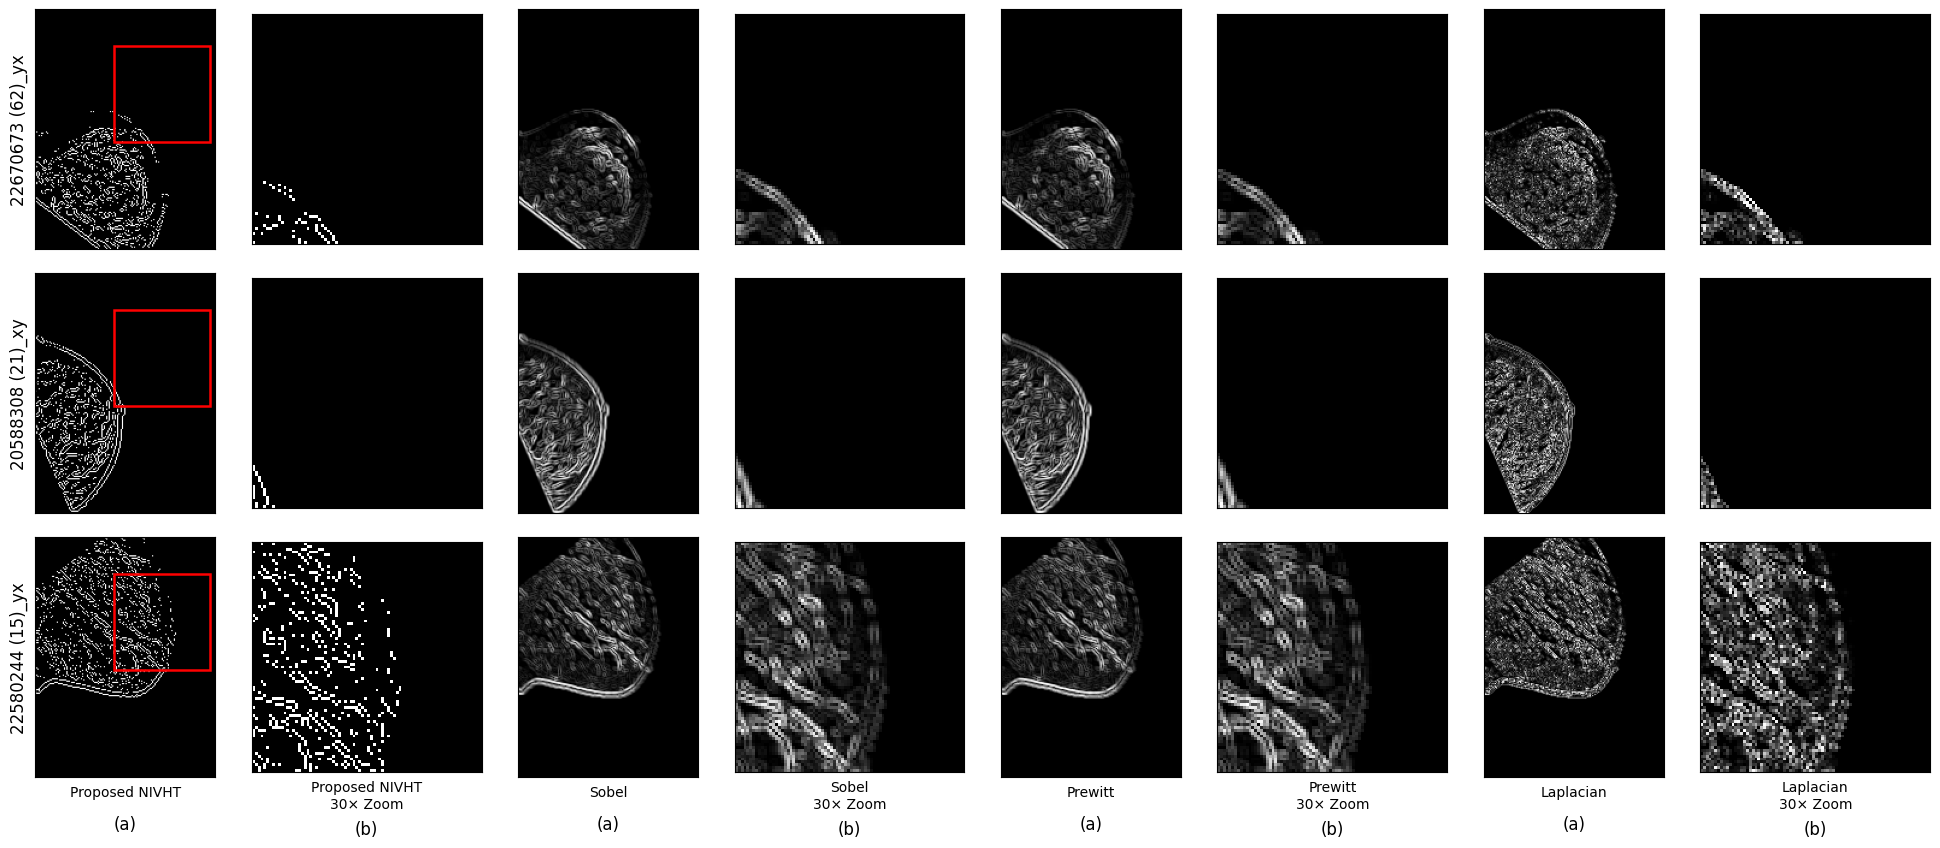

In [ ]:

# ===================== User Parameters =====================
combined_folder = f"{paths_results_data}/combined/"
zoom_factor = 30         # visual magnification is from cropping
crop_size   = 80         # width & height of zoom rectangle in pixels
max_images  = 3

# ---- Choose crop centre manually ----
manual_center = None     # e.g. (150, 200)
offset_x, offset_y = 30, -30
use_offset = True
# ===========================================================

def custom_zoom(img, crop_size, manual_center=None, offset=None):
    """Return cropped square and top-left coords for rectangle drawing."""
    h, w = img.shape[:2]
    cx, cy = w//2, h//2
    if manual_center is not None:
        cx, cy = manual_center
    elif offset is not None:
        cx += offset[0]
        cy += offset[1]
    half = crop_size // 2
    x1 = max(cx-half, 0); x2 = min(cx+half, w)
    y1 = max(cy-half, 0); y2 = min(cy+half, h)
    return img[y1:y2, x1:x2], (x1, y1)

# --- Collect images ---
combined_files = [f for f in os.listdir(combined_folder)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:max_images]
if not combined_files:
    raise FileNotFoundError(f"No images found in: {combined_folder}")

# --- Pre-compute edge maps for each image ---
all_results = []
for filename in combined_files:
    filepath = os.path.join(combined_folder, filename)
    orig_img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    if orig_img is None:
        print(f"⚠️ Skipping unreadable file: {filename}")
        continue

    img = cv2.bitwise_not(orig_img)  # Invert for visibility

    sobel_edges     = filters.sobel(img)
    prewitt_edges   = filters.prewitt(img)
    laplacian_edges = cv2.Laplacian(img, cv2.CV_64F)
    laplacian_edges = np.uint8(np.absolute(laplacian_edges))

    img_eq = cv2.equalizeHist(img)
    _, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)
    edges_canny = cv2.Canny(img, 50, 200)
    combined_edges = cv2.bitwise_and(edges_canny, high_intensity)
    skeleton = skeletonize(combined_edges > 0)
    thin_edges = img_as_ubyte(skeleton)

    methods = [
        ("Proposed NIVHT", thin_edges),
        ("Sobel",          sobel_edges),
        ("Prewitt",        prewitt_edges),
        ("Laplacian",      laplacian_edges)
    ]
    all_results.append((filename, orig_img, methods))

# === Plot all images in ONE grid ===
n_images  = len(all_results)
n_methods = len(all_results[0][2])
ncols     = n_methods * 2     # Full + Zoom for each method
nrows     = n_images

fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 3.2 * nrows))
if nrows == 1:  # keep axes 2-D
    axes = np.expand_dims(axes, axis=0)

plt.subplots_adjust(left=0.02, right=0.98,
                    top=0.92, bottom=0.12,
                    wspace=0.05, hspace=0.10)

for r, (filename, orig_img, methods) in enumerate(all_results):
    # Determine rectangle & crop once for the original image
    _, (rect_x, rect_y) = custom_zoom(orig_img, crop_size,
                                      manual_center if not use_offset else None,
                                      (offset_x, offset_y) if use_offset else None)

    for m, (label, edge_img) in enumerate(methods):
        if edge_img.dtype in [np.float32, np.float64]:
            edge_img = np.uint8(edge_img * 255)

        c_full = m * 2
        c_zoom = m * 2 + 1

        # ---------- Full image ----------
        ax_full = axes[r, c_full]
        ax_full.imshow(edge_img, cmap='gray')
        ax_full.set_xticks([]); ax_full.set_yticks([])

        # Draw red rectangle only on the ORIGINAL image column (first method)
        if m == 0:
            rect = patches.Rectangle((rect_x, rect_y), crop_size, crop_size,
                                     linewidth=1.8, edgecolor='red', facecolor='none')
            ax_full.add_patch(rect)

        # ---------- Zoomed patch ----------
        crop_patch, _ = custom_zoom(edge_img, crop_size,
                                    manual_center if not use_offset else None,
                                    (offset_x, offset_y) if use_offset else None)
        ax_zoom = axes[r, c_zoom]
        ax_zoom.imshow(crop_patch, cmap='gray', interpolation='nearest')
        ax_zoom.set_xticks([]); ax_zoom.set_yticks([])

        # ✅ Labels only for the LAST row
        if r == nrows - 1:
            ax_full.set_xlabel(f"{label}", fontsize=10, labelpad=6)
            ax_zoom.set_xlabel(f"{label}\n{zoom_factor}× Zoom", fontsize=10, labelpad=6)

    # filename as row label at left
    axes[r, 0].set_ylabel(os.path.splitext(filename)[0],fontsize=12, rotation=90, labelpad=5)

# ---------- (a) and (b) markers under last row only ----------
last_row = nrows - 1
for m in range(n_methods):
    c_full = m * 2
    c_zoom = m * 2 + 1
    ax_full = axes[last_row, c_full]
    ax_zoom = axes[last_row, c_zoom]

    fig.text(ax_full.get_position().x0 + ax_full.get_position().width/2,
             ax_full.get_position().y0 - 0.04,"(a)", ha='center', va='top', fontsize=12)

    fig.text(ax_zoom.get_position().x0 + ax_zoom.get_position().width/2,
             ax_zoom.get_position().y0 - 0.05,"(b)", ha='center', va='top', fontsize=12)

plt.show()


## DONE

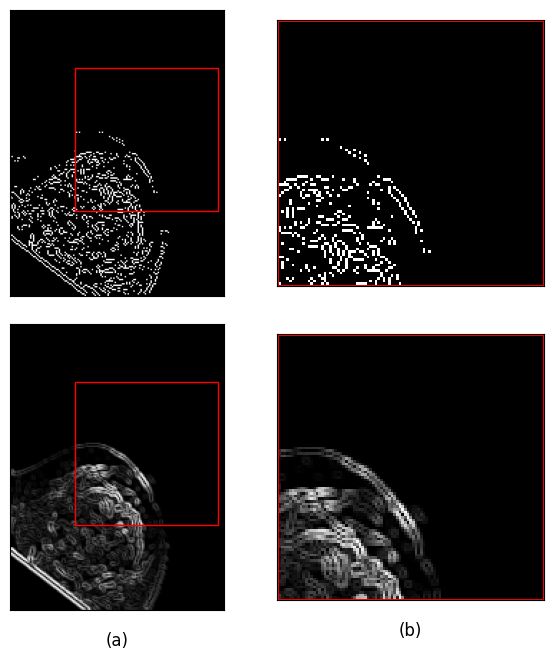

In [29]:

# ===================== User Parameters =====================
combined_folder = f"{paths_results_data}/combined/"
zoom_factor = 60         # label only – visual magnification is from cropping
crop_size   = 100         # width & height of zoom rectangle in pixels
classical_method = "Sobel"   # <<< choose "Sobel" or "Laplacian"
# ---- Choose crop centre manually ----
manual_center = None         # e.g. (150, 200) or None for offset
offset_x, offset_y = 20, -10
use_offset = True
# ===========================================================

def custom_zoom(img, crop_size, manual_center=None, offset=None):
    """Return cropped square and top-left coords for rectangle drawing."""
    h, w = img.shape[:2]
    cx, cy = w//2, h//2
    if manual_center is not None:
        cx, cy = manual_center
    elif offset is not None:
        cx += offset[0]
        cy += offset[1]
    half = crop_size // 2
    x1 = max(cx-half, 0); x2 = min(cx+half, w)
    y1 = max(cy-half, 0); y2 = min(cy+half, h)
    return img[y1:y2, x1:x2], (x1, y1)

# ---------- Load only ONE image ----------
combined_files = [f for f in os.listdir(combined_folder)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
if not combined_files:
    raise FileNotFoundError(f"No images found in: {combined_folder}")

filename = combined_files[0]
filepath = os.path.join(combined_folder, filename)
orig_img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
if orig_img is None:
    raise ValueError(f"Could not read image: {filename}")

# Invert for visibility
img = cv2.bitwise_not(orig_img)

# --- Proposed NIVHT edges ---
img_eq = cv2.equalizeHist(img)
_, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)
edges_canny = cv2.Canny(img, 50, 200)
combined_edges = cv2.bitwise_and(edges_canny, high_intensity)
skeleton = skeletonize(combined_edges > 0)
nivht_edges = img_as_ubyte(skeleton)

# --- Classical filter edges ---
if classical_method.lower() == "sobel":
    classical_edges = filters.sobel(img)
elif classical_method.lower() == "laplacian":
    lap = cv2.Laplacian(img, cv2.CV_64F)
    classical_edges = np.uint8(np.absolute(lap))
else:
    raise ValueError("classical_method must be 'Sobel' or 'Laplacian'")

if classical_edges.dtype in [np.float32, np.float64]:
    classical_edges = np.uint8(classical_edges * 255)

methods = [
    ("Proposed NIVHT", nivht_edges),
    (classical_method, classical_edges)
]

# === Plot in grid: 2 rows (methods) x 2 cols (full + zoom) ===
n_methods = len(methods)
ncols = 2  # full + zoom
nrows = n_methods

fig, axes = plt.subplots(nrows, ncols, figsize=(8, 8))
if nrows == 1:   # keep axes 2-D
    axes = np.expand_dims(axes, axis=0)

plt.subplots_adjust(left=0.15, right=0.85,
                    top=0.9, bottom=0.15,
                    wspace=0.1, hspace=0.1)

for r, (label, edge_img) in enumerate(methods):
    # Determine rectangle & crop
    _, (rect_x, rect_y) = custom_zoom(orig_img, crop_size,
                                      manual_center if not use_offset else None,
                                      (offset_x, offset_y) if use_offset else None)

    if edge_img.dtype in [np.float32, np.float64]:
        edge_img = np.uint8(edge_img * 255)

    # ---- Full image with rectangle ----
    ax_full = axes[r, 0]
    ax_full.imshow(edge_img, cmap='gray')
    ax_full.set_xticks([]); ax_full.set_yticks([])

    rect = patches.Rectangle((rect_x, rect_y), crop_size, crop_size,
                             linewidth=1, edgecolor='red', facecolor='none')
    ax_full.add_patch(rect)

    # ---- Zoomed patch ----
    # ---- Zoomed patch ----
    crop_patch, _ = custom_zoom(edge_img, crop_size,
                                manual_center if not use_offset else None,
                                (offset_x, offset_y) if use_offset else None)
    ax_zoom = axes[r, 1]
    ax_zoom.imshow(crop_patch, cmap='gray', interpolation='nearest')
    ax_zoom.set_xticks([]); ax_zoom.set_yticks([])

    # ✅ Ensure axis limits match the pixel grid so border is fully visible
    h, w = crop_patch.shape[:2]
    ax_zoom.set_xlim(0, w)
    ax_zoom.set_ylim(h, 0)   # flip Y to match image coordinates

    # 🔴 Red border fully around the zoomed image
    border = patches.Rectangle(
        (0, 0), w, h,
        linewidth=2, edgecolor='red', facecolor='none'
    )
    ax_zoom.add_patch(border)


    # 🔴 Add red border around the zoomed patch itself
    border = patches.Rectangle(
        (0, 0), crop_patch.shape[1], crop_patch.shape[0],
        linewidth=2, edgecolor='red', facecolor='none'
    )
    ax_zoom.add_patch(border)

# ---------- (a) and (b) markers under last row ----------
last_row = nrows - 1
ax_full = axes[last_row, 0]
ax_zoom = axes[last_row, 1]

fig.text(ax_full.get_position().x0 + ax_full.get_position().width/2,
         ax_full.get_position().y0 - 0.05,
         "(a)", ha='center', va='bottom', fontsize=12)

fig.text(ax_zoom.get_position().x0 + ax_zoom.get_position().width/2,
         ax_zoom.get_position().y0 - 0.05,
         "(b)", ha='center', va='bottom', fontsize=12)

plt.show()


## DONE

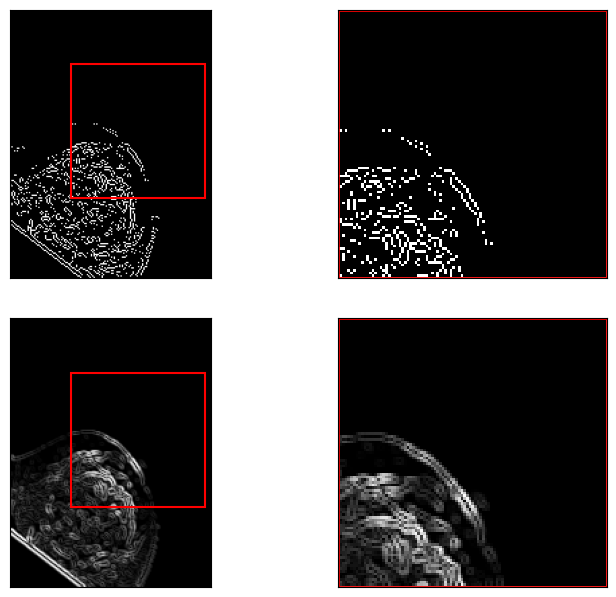

Displayed zoomed comparison for 22670673 (62)_yx.png with crop size 100 and zoom factor 60×.


In [32]:
# ===================== User Parameters =====================
combined_folder = f"{paths_results_data}/combined/"
zoom_factor     = 60        # (kept for reference; not used for text)
crop_size       = 100       # width & height of zoom rectangle in pixels
classical_method = "Sobel"  # <<< choose "Sobel" or "Laplacian"

# ---- Choose crop centre manually ----
manual_center   = None      # e.g. (150, 200) or None for offset
offset_x, offset_y = 20, -10
use_offset      = True
# ===========================================================

def custom_zoom(img, crop_size, manual_center=None, offset=None):
    """Return cropped square and top-left coords for rectangle drawing."""
    h, w = img.shape[:2]
    cx, cy = w//2, h//2
    if manual_center is not None:
        cx, cy = manual_center
    elif offset is not None:
        cx += offset[0]
        cy += offset[1]
    half = crop_size // 2
    x1 = max(cx-half, 0); x2 = min(cx+half, w)
    y1 = max(cy-half, 0); y2 = min(cy+half, h)
    return img[y1:y2, x1:x2], (x1, y1)

# ---------- Load only ONE image ----------
combined_files = [f for f in os.listdir(combined_folder)
                  if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
if not combined_files:
    raise FileNotFoundError(f"No images found in: {combined_folder}")

filename = combined_files[0]
filepath = os.path.join(combined_folder, filename)
orig_img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
if orig_img is None:
    raise ValueError(f"Could not read image: {filename}")

# Invert for visibility
img = cv2.bitwise_not(orig_img)

# --- Proposed NIVHT edges ---
img_eq = cv2.equalizeHist(img)
_, high_intensity = cv2.threshold(img_eq, 100, 255, cv2.THRESH_BINARY)
edges_canny = cv2.Canny(img, 50, 200)
combined_edges = cv2.bitwise_and(edges_canny, high_intensity)
skeleton = skeletonize(combined_edges > 0)
nivht_edges = img_as_ubyte(skeleton)

# --- Classical filter edges ---
if classical_method.lower() == "sobel":
    classical_edges = filters.sobel(img)
elif classical_method.lower() == "laplacian":
    lap = cv2.Laplacian(img, cv2.CV_64F)
    classical_edges = np.uint8(np.absolute(lap))
else:
    raise ValueError("classical_method must be 'Sobel' or 'Laplacian'")

if classical_edges.dtype in [np.float32, np.float64]:
    classical_edges = np.uint8(classical_edges * 255)

methods = [
    ("Proposed NIVHT", nivht_edges),
    (classical_method, classical_edges)
]

# === Plot grid: for each method -> 2 columns:
#     Full image | Zoomed patch
n_methods = len(methods)
ncols = 2
nrows = n_methods

fig, axes = plt.subplots(nrows, ncols, figsize=(7, 10.5))
if nrows == 1:
    axes = np.expand_dims(axes, axis=0)

plt.subplots_adjust(left=0.02, right=0.96,
                    top=0.6, bottom=0.05,
                    wspace=0.22, hspace=0.15)

for r, (_, edge_img) in enumerate(methods):
    _, (rect_x, rect_y) = custom_zoom(orig_img, crop_size,
                                      manual_center if not use_offset else None,
                                      (offset_x, offset_y) if use_offset else None)

    if edge_img.dtype in [np.float32, np.float64]:
        edge_img = np.uint8(edge_img * 255)

    # ---- Full image with rectangle ----
    ax_full = axes[r, 0]
    ax_full.imshow(edge_img, cmap='gray')
    ax_full.set_xticks([]); ax_full.set_yticks([])

    rect = patches.Rectangle((rect_x, rect_y), crop_size, crop_size,
                             linewidth=1.5, edgecolor='red', facecolor='none')
    ax_full.add_patch(rect)

    # ---- Zoomed patch ----
    crop_patch, _ = custom_zoom(edge_img, crop_size,
                                manual_center if not use_offset else None,
                                (offset_x, offset_y) if use_offset else None)
    ax_zoom = axes[r, 1]
    ax_zoom.imshow(crop_patch, cmap='gray', interpolation='nearest')
    ax_zoom.set_xticks([]); ax_zoom.set_yticks([])

    h, w = crop_patch.shape[:2]
    ax_zoom.set_xlim(0, w)
    ax_zoom.set_ylim(h, 0)   # flip Y to match image coords
    border = patches.Rectangle((0, 0), w, h,
                               linewidth=2, edgecolor='red', facecolor='none')
    ax_zoom.add_patch(border)

plt.show()

print(f"Displayed zoomed comparison for {filename} with crop size {crop_size} and zoom factor {zoom_factor}×.")
